In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Load our master analytical dataset
master = pd.read_csv(
    "../data/processed/us_macro_etf_master_2008_2025.csv",
    parse_dates=["observation_date"]
)

master = master.sort_values(
    "observation_date"
).reset_index(drop=True)

assets = ["SPY", "IEF", "GLD"]

# Portfolio target weights
weights = pd.DataFrame(
    {
        "SPY": [1.00, 0.60, 0.60],
        "IEF": [0.00, 0.40, 0.20],
        "GLD": [0.00, 0.00, 0.20]
    },
    index=[
        "100% Equity",
        "Traditional 60/40",
        "Diversified 60/20/20"
    ]
)

# Validate portfolio weights
assert np.allclose(weights.sum(axis=1), 1.0)
assert (weights >= 0).all().all()

print("Portfolio Allocation Weights:")
display((weights * 100).round(1))

# ETF returns are stored in percentage units
# Example: 2.5 means +2.5%, not +250%

assert master[assets].notna().all().all()
assert len(master) == 216
assert master["observation_date"].is_unique

# Calculate monthly portfolio returns (%)
# This assumes monthly rebalancing to target weights

portfolio_monthly_returns = pd.DataFrame(
    master[assets].to_numpy() @ weights.T.to_numpy(),
    columns=weights.index
)

portfolio_monthly_returns.insert(
    0,
    "observation_date",
    master["observation_date"]
)

# Validation: 100% Equity must equal SPY
assert np.allclose(
    portfolio_monthly_returns["100% Equity"],
    master["SPY"]
)

print("\nFirst 5 Months of Portfolio Returns (%):")
display(portfolio_monthly_returns.head().round(3))

print("\nLast 5 Months of Portfolio Returns (%):")
display(portfolio_monthly_returns.tail().round(3))

print("\nTotal months:", len(portfolio_monthly_returns))


Portfolio Allocation Weights:


,SPY,IEF,GLD
100% Equity,100.0,0.0,0.0
Traditional 60/40,60.0,40.0,0.0
Diversified 60/20/20,60.0,20.0,20.0



First 5 Months of Portfolio Returns (%):


,observation_date,100% Equity,Traditional 60/40,Diversified 60/20/20
0,2008-01-01,-6.046,-2.285,-0.788
1,2008-02-01,-2.584,-1.055,-0.257
2,2008-03-01,-0.894,-0.002,-1.469
3,2008-04-01,4.766,1.893,1.545
4,2008-05-01,1.512,0.196,0.736



Last 5 Months of Portfolio Returns (%):


,observation_date,100% Equity,Traditional 60/40,Diversified 60/20/20
211,2025-08-01,2.052,1.890,2.558
212,2025-09-01,3.562,2.398,4.619
213,2025-10-01,2.384,1.715,2.284
214,2025-11-01,0.195,0.512,1.388
215,2025-12-01,0.080,-0.257,0.330



Total months: 216


In [2]:

# DAY 8 — Portfolio Risk & Performance Metrics

# 1. Load historical risk-free rate
rf = pd.read_csv(
    "../data/processed/us_3m_treasury_yield_2007_2025.csv",
    parse_dates=["observation_date"]
)

rf["month"] = rf["observation_date"].dt.to_period("M")

rf = rf.sort_values("month").copy()

# GS3M is annualized and expressed in percent.
# Approximate monthly risk-free return using
# the previous month's Treasury yield.
rf["risk_free_monthly_pct"] = (
    rf["GS3M"].shift(1) / 12
)

# 2. Align with portfolio returns
portfolio_data = portfolio_monthly_returns.copy()

portfolio_data["month"] = (
    portfolio_data["observation_date"].dt.to_period("M")
)

portfolio_data = portfolio_data.merge(
    rf[["month", "risk_free_monthly_pct"]],
    on="month",
    how="left",
    validate="one_to_one"
)

assert len(portfolio_data) == 216
assert portfolio_data["risk_free_monthly_pct"].notna().all()

# 3. Calculate performance metrics
portfolio_names = list(weights.index)

performance_results = []

for name in portfolio_names:

    # Percentage returns -> decimal returns
    monthly_returns = portfolio_data[name] / 100

    n = len(monthly_returns)

    # Cumulative wealth starting at 1
    wealth = (1 + monthly_returns).cumprod()

    # CAGR
    cagr = wealth.iloc[-1] ** (12 / n) - 1

    # Annualized volatility
    annual_vol = monthly_returns.std(ddof=1) * np.sqrt(12)

    # Monthly excess returns, in percentage units
    excess_returns = (
        portfolio_data[name]
        - portfolio_data["risk_free_monthly_pct"]
    )

    # Annualized Sharpe ratio
    sharpe = (
        excess_returns.mean()
        / excess_returns.std(ddof=1)
        * np.sqrt(12)
    )

    # Maximum drawdown:
    # Include the initial portfolio value of 1
    running_peak = np.maximum(
        1.0,
        wealth.cummax()
    )

    drawdowns = wealth / running_peak - 1
    max_drawdown = drawdowns.min()

    performance_results.append({
        "Portfolio": name,
        "CAGR (%)": cagr * 100,
        "Annual Volatility (%)": annual_vol * 100,
        "Sharpe Ratio": sharpe,
        "Max Drawdown (%)": max_drawdown * 100,
        "Final Wealth ($100)": wealth.iloc[-1] * 100
    })

portfolio_performance = pd.DataFrame(
    performance_results
).set_index("Portfolio")

print("PORTFOLIO PERFORMANCE — 2008 TO 2025")
display(portfolio_performance.round(3))

print("\nRisk-free observations aligned:",
      portfolio_data["risk_free_monthly_pct"].count())

# Validate benchmark portfolio
assert np.isclose(
    portfolio_data["100% Equity"].iloc[0],
    master["SPY"].iloc[0]
)


PORTFOLIO PERFORMANCE — 2008 TO 2025


,CAGR (%),Annual Volatility (%),Sharpe Ratio,Max Drawdown (%),Final Wealth ($100)
Portfolio,,,,,
100% Equity,10.972,15.674,0.659,-48.219,651.340
Traditional 60/40,8.114,9.626,0.720,-28.490,407.252
Diversified 60/20/20,9.541,10.397,0.803,-28.116,515.680



Risk-free observations aligned: 216


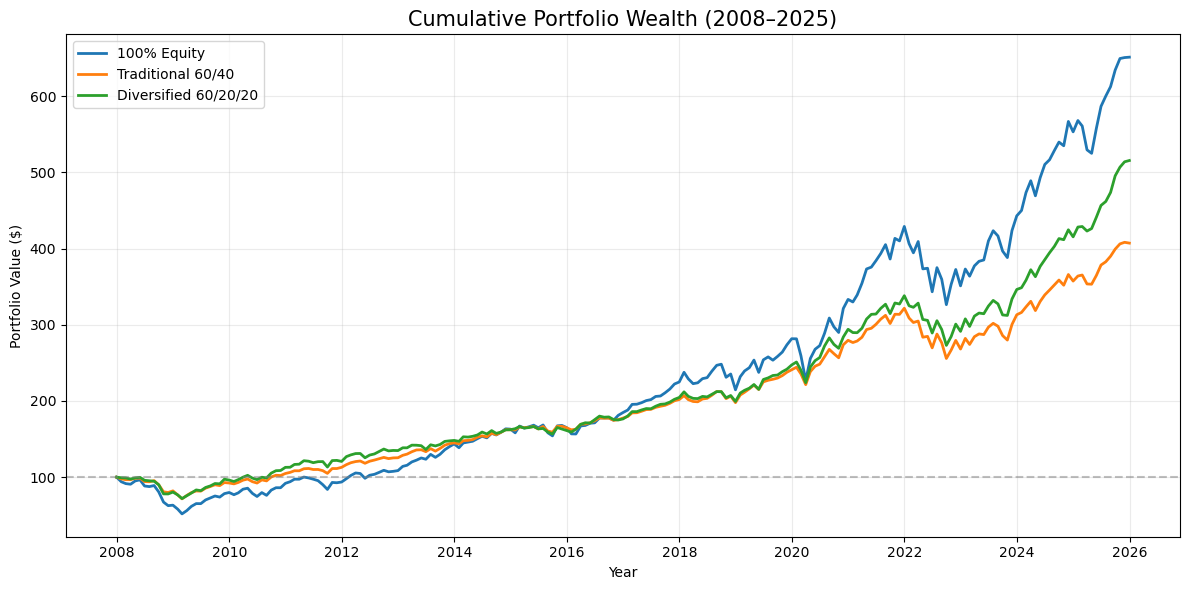

Final Portfolio Wealth ($100 invested):


,100% Equity,Traditional 60/40,Diversified 60/20/20
2025-12-31,651.34,407.25,515.68


In [3]:

# DAY 8 — Cumulative Portfolio Wealth

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from pathlib import Path

portfolio_names = list(weights.index)

# Convert percentage returns to decimal returns
monthly_decimal = (
    portfolio_data[portfolio_names] / 100
)

# Calculate cumulative growth of $100
portfolio_wealth = (
    100 * (1 + monthly_decimal).cumprod()
)

# ETF observations represent month-end prices.
# Convert monthly period labels to month-end dates.
portfolio_wealth.index = (
    portfolio_data["month"]
    .dt.to_timestamp(how="end")
    .dt.normalize()
)

# Include the initial $100 before January 2008
initial_date = (
    (portfolio_data["month"].iloc[0] - 1)
    .to_timestamp(how="end")
    .normalize()
)

initial_wealth = pd.DataFrame(
    {name: [100.0] for name in portfolio_names},
    index=[initial_date]
)

portfolio_wealth = pd.concat(
    [initial_wealth, portfolio_wealth]
)

# Create cumulative wealth chart
fig, ax = plt.subplots(figsize=(12, 6))

for name in portfolio_names:
    ax.plot(
        portfolio_wealth.index,
        portfolio_wealth[name],
        linewidth=2,
        label=name
    )

ax.axhline(
    100,
    linestyle="--",
    color="gray",
    alpha=0.5
)

ax.set_title(
    "Cumulative Portfolio Wealth (2008–2025)",
    fontsize=15
)

ax.set_xlabel("Year")
ax.set_ylabel("Portfolio Value ($)")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

# Save figure
figures_dir = Path("../reports/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    figures_dir / "portfolio_cumulative_wealth_2008_2025.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# Validate terminal wealth
print("Final Portfolio Wealth ($100 invested):")
display(portfolio_wealth.tail(1).round(2))

assert np.allclose(
    portfolio_wealth.iloc[-1].to_numpy(),
    portfolio_performance.loc[
        portfolio_names, "Final Wealth ($100)"
    ].to_numpy(),
    atol=0.01
)


In [4]:

# DAY 8 — Portfolio Performance by Inflation Regime

# Merge portfolio returns with inflation regimes
regime_portfolios = portfolio_data.merge(
    master[["observation_date", "inflation_regime"]],
    on="observation_date",
    how="left",
    validate="one_to_one"
)

regime_order = [
    "Low Inflation",
    "Moderate Inflation",
    "High Inflation"
]

regime_groups = regime_portfolios.groupby(
    "inflation_regime",
    observed=True
)

# Number of months
regime_counts = (
    regime_groups.size()
    .reindex(regime_order)
)

# Mean monthly portfolio returns (%)
portfolio_regime_means = (
    regime_groups[portfolio_names]
    .mean()
    .reindex(regime_order)
)

# Monthly portfolio volatility (%)
portfolio_regime_volatility = (
    regime_groups[portfolio_names]
    .std(ddof=1)
    .reindex(regime_order)
)

# Relative advantage of gold allocation
portfolio_regime_means["Gold Advantage (pp)"] = (
    portfolio_regime_means["Diversified 60/20/20"]
    - portfolio_regime_means["Traditional 60/40"]
)

print("OBSERVATIONS BY INFLATION REGIME:")
display(regime_counts)

print("\nMEAN MONTHLY PORTFOLIO RETURNS (%):")
display(portfolio_regime_means.round(3))

print("\nMONTHLY PORTFOLIO VOLATILITY (%):")
display(portfolio_regime_volatility.round(3))

# Validation
assert regime_counts.sum() == 215
assert len(regime_portfolios) == 216


OBSERVATIONS BY INFLATION REGIME:


inflation_regime
Low Inflation         96
Moderate Inflation    86
High Inflation        33
dtype: int64


MEAN MONTHLY PORTFOLIO RETURNS (%):


,100% Equity,Traditional 60/40,Diversified 60/20/20,Gold Advantage (pp)
inflation_regime,,,,
Low Inflation,1.476,1.017,1.090,0.073
Moderate Inflation,0.916,0.685,0.810,0.125
High Inflation,-0.375,-0.272,-0.066,0.206



MONTHLY PORTFOLIO VOLATILITY (%):


,100% Equity,Traditional 60/40,Diversified 60/20/20
inflation_regime,,,
Low Inflation,4.481,2.596,2.857
Moderate Inflation,4.185,2.517,2.868
High Inflation,5.359,3.706,3.654


In [5]:

# DAY 8 — Historical Portfolio Stress Tests

stress_years = [2008, 2020, 2022]

stress_results = []

for year in stress_years:

    yearly_data = portfolio_data.loc[
        portfolio_data["observation_date"].dt.year == year
    ].copy()

    assert len(yearly_data) == 12

    for portfolio in portfolio_names:

        # Monthly decimal returns
        returns = (
            yearly_data[portfolio].to_numpy()
            / 100
        )

        # Calendar-year compounded return
        total_return = (
            np.prod(1 + returns) - 1
        ) * 100

        # Monthly volatility
        volatility = (
            np.std(returns, ddof=1) * 100
        )

        # Include initial wealth at start of year
        wealth = np.concatenate([
            [1.0],
            np.cumprod(1 + returns)
        ])

        running_peak = np.maximum.accumulate(
            wealth
        )

        drawdowns = (
            wealth / running_peak - 1
        )

        max_drawdown = (
            drawdowns.min() * 100
        )

        worst_month = (
            returns.min() * 100
        )

        stress_results.append({
            "Year": year,
            "Portfolio": portfolio,
            "Annual Return (%)": total_return,
            "Monthly Volatility (%)": volatility,
            "Max Drawdown (%)": max_drawdown,
            "Worst Month (%)": worst_month
        })

stress_test_results = pd.DataFrame(
    stress_results
)

print("HISTORICAL PORTFOLIO STRESS TESTS:")
display(stress_test_results.round(3))

# Compare the two diversified portfolios
stress_comparison = (
    stress_test_results.pivot(
        index="Year",
        columns="Portfolio",
        values="Annual Return (%)"
    )
)

stress_comparison["Gold Advantage (pp)"] = (
    stress_comparison["Diversified 60/20/20"]
    - stress_comparison["Traditional 60/40"]
)

print("\nANNUAL RETURN COMPARISON:")
display(stress_comparison.round(3))


HISTORICAL PORTFOLIO STRESS TESTS:


,Year,Portfolio,Annual Return (%),Monthly Volatility (%),Max Drawdown (%),Worst Month (%)
0,2008,100% Equity,-36.795,6.029,-37.408,-16.519
1,2008,Traditional 60/40,-18.007,3.684,-20.124,-10.256
2,2008,Diversified 60/20/20,-19.582,4.236,-22.049,-13.312
3,2020,100% Equity,18.332,7.435,-19.448,-12.487
4,2020,Traditional 60/40,16.039,4.117,-9.354,-6.003
5,2020,Diversified 60/20/20,18.940,4.683,-10.786,-6.792
6,2022,100% Equity,-18.175,6.657,-23.927,-9.245
7,2022,Traditional 60/40,-16.651,4.739,-20.508,-7.441
8,2022,Diversified 60/20/20,-13.848,4.596,-19.285,-7.071



ANNUAL RETURN COMPARISON:


Portfolio,100% Equity,Diversified 60/20/20,Traditional 60/40,Gold Advantage (pp)
Year,,,,
2008,-36.795,-19.582,-18.007,-1.575
2020,18.332,18.940,16.039,2.900
2022,-18.175,-13.848,-16.651,2.803


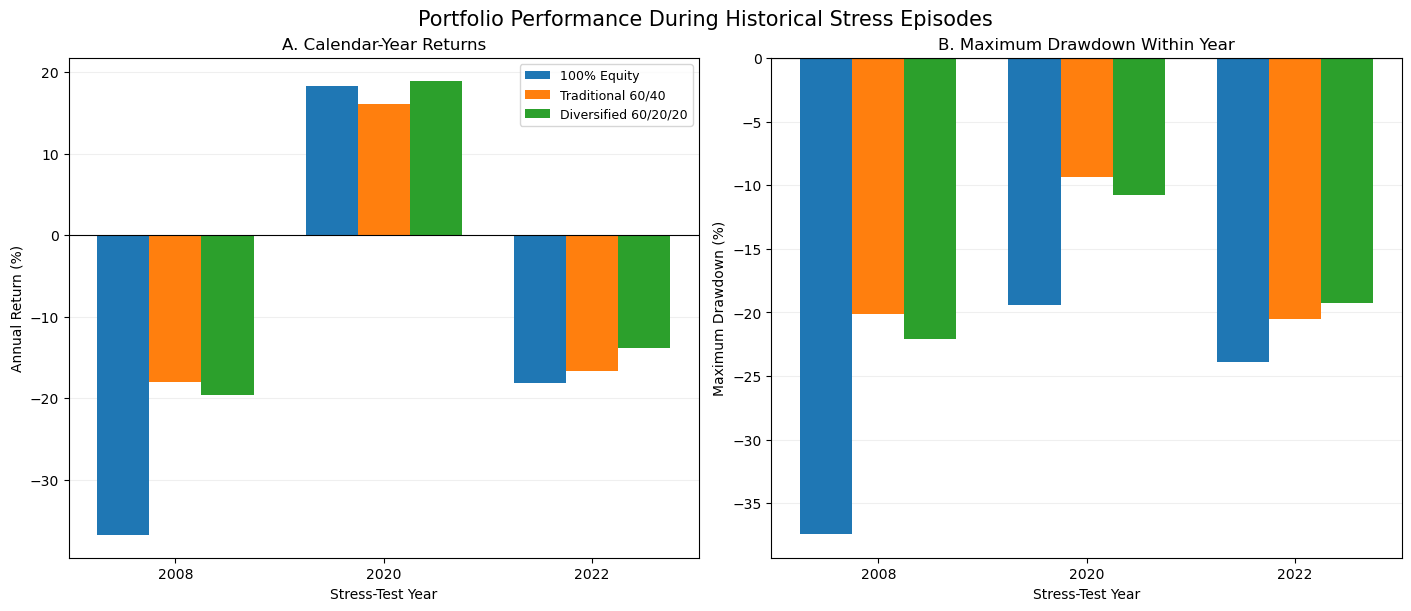

DAY 8 RESULTS SAVED SUCCESSFULLY
Stress-test observations: 9
Portfolios: 3
Months: 216


In [6]:

# DAY 8 — Final Figures and Data Exports

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

tables_dir = Path("../reports/tables")
figures_dir = Path("../reports/figures")
processed_dir = Path("../data/processed")

for folder in [tables_dir, figures_dir, processed_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# 1. Save portfolio returns
portfolio_monthly_returns.to_csv(
    processed_dir / "portfolio_monthly_returns_2008_2025.csv",
    index=False
)

# 2. Save portfolio allocation and performance
weights.to_csv(
    tables_dir / "portfolio_allocation_weights.csv",
    index_label="Portfolio"
)

portfolio_performance.to_csv(
    tables_dir / "portfolio_performance_2008_2025.csv",
    index_label="Portfolio"
)

# 3. Save inflation regime analysis
portfolio_regime_means.to_csv(
    tables_dir / "portfolio_inflation_regime_returns.csv",
    index_label="inflation_regime"
)

portfolio_regime_volatility.to_csv(
    tables_dir / "portfolio_inflation_regime_volatility.csv",
    index_label="inflation_regime"
)

# 4. Save stress test results
stress_test_results.to_csv(
    tables_dir / "portfolio_stress_tests.csv",
    index=False
)

stress_comparison.to_csv(
    tables_dir / "portfolio_stress_comparison.csv",
    index_label="Year"
)

# 5. Build comparison chart
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6),
    layout="constrained"
)

years = [2008, 2020, 2022]
x = np.arange(len(years))
bar_width = 0.25

annual_returns = stress_test_results.pivot(
    index="Year",
    columns="Portfolio",
    values="Annual Return (%)"
).reindex(index=years, columns=portfolio_names)

drawdowns = stress_test_results.pivot(
    index="Year",
    columns="Portfolio",
    values="Max Drawdown (%)"
).reindex(index=years, columns=portfolio_names)

for i, portfolio in enumerate(portfolio_names):

    offset = (i - 1) * bar_width

    axes[0].bar(
        x + offset,
        annual_returns[portfolio],
        width=bar_width,
        label=portfolio
    )

    axes[1].bar(
        x + offset,
        drawdowns[portfolio],
        width=bar_width,
        label=portfolio
    )

axes[0].set_title("A. Calendar-Year Returns")
axes[0].set_ylabel("Annual Return (%)")

axes[1].set_title("B. Maximum Drawdown Within Year")
axes[1].set_ylabel("Maximum Drawdown (%)")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(years)
    ax.set_xlabel("Stress-Test Year")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].legend(fontsize=9)

fig.suptitle(
    "Portfolio Performance During Historical Stress Episodes",
    fontsize=15
)

fig.savefig(
    figures_dir / "portfolio_historical_stress_tests.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# 6. Final validation
assert len(portfolio_monthly_returns) == 216
assert len(stress_test_results) == 9
assert np.allclose(weights.sum(axis=1), 1.0)

print("DAY 8 RESULTS SAVED SUCCESSFULLY")
print("Stress-test observations:", len(stress_test_results))
print("Portfolios:", len(portfolio_names))
print("Months:", len(portfolio_monthly_returns))



## Day 8 — Key Findings and Economic Interpretation

### 1. Research Objective

This analysis investigates whether diversified portfolios
improved historical risk-adjusted performance across
different macroeconomic environments during 2008–2025.

Three portfolios were constructed:

- 100% Equity: 100% SPY
- Traditional 60/40: 60% SPY, 40% IEF
- Diversified 60/20/20: 60% SPY, 20% IEF, 20% GLD

Portfolios were rebalanced monthly to their target weights.

### 2. Overall Portfolio Performance

Over the full sample, the 100% Equity portfolio achieved
the highest CAGR (10.972%) but experienced substantial
volatility (15.674%) and a maximum drawdown of -48.219%.

The Traditional 60/40 portfolio achieved:

- CAGR: 8.114%
- Annualized volatility: 9.626%
- Sharpe ratio: 0.720
- Maximum drawdown: -28.490%

The Diversified 60/20/20 portfolio achieved:

- CAGR: 9.541%
- Annualized volatility: 10.397%
- Sharpe ratio: 0.803
- Maximum drawdown: -28.116%

Replacing half of the bond allocation with gold was
associated with higher historical returns and a higher
Sharpe ratio.

However, the gold allocation increased full-sample
volatility relative to the Traditional 60/40 portfolio.

### 3. Portfolio Performance Across Inflation Regimes

Mean monthly returns during high-inflation months were:

- 100% Equity: -0.375%
- Traditional 60/40: -0.272%
- Diversified 60/20/20: -0.066%

The Diversified portfolio outperformed the Traditional
60/40 portfolio in average monthly returns across all
three inflation regimes.

Its mean monthly return advantage was:

- Low Inflation: +0.073 percentage points
- Moderate Inflation: +0.125 percentage points
- High Inflation: +0.206 percentage points

However, the Diversified portfolio exhibited greater
volatility during low- and moderate-inflation months.

During high inflation, its volatility was slightly lower
(3.654% versus 3.706%), a small difference that has not
been statistically validated.

### 4. Historical Stress Tests

#### 2008 — Global Financial Crisis

The Traditional 60/40 portfolio outperformed the
Diversified 60/20/20 portfolio.

Annual returns:

- Traditional 60/40: -18.007%
- Diversified 60/20/20: -19.582%

The Traditional portfolio also experienced lower
volatility and a smaller drawdown.

This illustrates that replacing bonds with gold does
not necessarily improve protection in every crisis.

#### 2020 — COVID-19 Shock

Annual returns:

- Traditional 60/40: +16.039%
- Diversified 60/20/20: +18.940%

The gold allocation improved annual performance,
but the Diversified portfolio exhibited higher
volatility and a deeper intra-year drawdown.

#### 2022 — Inflation and Monetary Tightening

Annual returns:

- 100% Equity: -18.175%
- Traditional 60/40: -16.651%
- Diversified 60/20/20: -13.848%

The Diversified portfolio outperformed the Traditional
60/40 by 2.803 percentage points.

It also experienced slightly lower volatility and
a smaller maximum drawdown.

These results are consistent with the earlier finding
that stock-bond diversification was weaker during
the high-inflation episode.

However, this does not establish a causal effect
of inflation or monetary policy on portfolio returns.

### 5. Methodological Limitations

- Portfolio weights were evaluated retrospectively.
- All portfolios assume monthly rebalancing.
- Trading costs, taxes, and rebalancing costs are excluded.
- ETF returns reflect historical total-return-adjusted
  market data rather than investor-specific realized returns.
- Risk-adjusted performance uses an approximate monthly
  risk-free rate derived from the previous month's GS3M.
- Portfolio comparisons are in-sample and do not establish
  out-of-sample superiority.
- Inflation regimes are classified using realized
  contemporaneous CPI inflation, not real-time signals.
- High-inflation observations are concentrated in a small
  number of historical episodes.
- Stress-test years were selected retrospectively.
- Portfolio performance differences have not yet been
  tested for statistical significance.
- Past portfolio performance does not guarantee
  future results.

### 6. Main Research Conclusion

During 2008–2025, replacing part of a traditional
stock-bond allocation with gold improved the observed
Sharpe ratio and cumulative return.

However, the benefits differed across historical
economic environments.

The Traditional 60/40 portfolio provided stronger
protection during 2008, while the Diversified 60/20/20
portfolio performed better during the 2022 inflation shock.

These findings suggest that diversification effectiveness
depends on the interaction between asset returns,
correlations, and prevailing market conditions.

The results are descriptive and should not be interpreted
as evidence that one allocation is universally superior.

### 7. Next Research Stage

Day 9 will investigate portfolio robustness through:

- Subperiod performance comparisons
- Alternative portfolio allocations
- Rebalancing assumptions and turnover
- Sensitivity to specific historical periods
- Assessment of the stability of the gold advantage

The objective is to evaluate whether the historical
outperformance of the Diversified portfolio is robust
enough to support broader investment conclusions.
